In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load your dataset
df = pd.read_csv("real_india_ev_range_dataset.csv")

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df

Dataset Shape: 7291 rows, 25 columns


,make,model,variant,battery_capacity_kWh,battery_capacity_kWh_new,motor_power_kW,vehicle_weight_kg,drag_coefficient_Cd,frontal_area_m2,rolling_resistance_Cr,...,terrain_type,traffic_condition,driving_style,passengers,battery_age_years,tyre_pressure_deviation_psi,city_road_type,energy_consumption_kWh_per_km,real_world_range_km,price_lakh_INR
0,Tata,Nexon EV,Long Range,35.3,40.5,105,1610,0.34,2.4,0.0122,...,0,2,0,1,4.3,-2,Delhi,0.2504,141.00,17.5
1,Tata,Nexon EV,Long Range,40.5,40.5,105,1610,0.34,2.4,0.0120,...,0,2,1,3,0.0,0,Delhi,0.1198,338.00,17.5
2,Tata,Nexon EV,Long Range,39.3,40.5,105,1610,0.34,2.4,0.0122,...,0,1,1,3,1.0,-2,Delhi,0.1254,313.40,17.5
3,Tata,Nexon EV,Long Range,39.0,40.5,105,1610,0.34,2.4,0.0120,...,0,0,1,1,1.2,0,Delhi,0.0883,441.75,17.5
4,Tata,Nexon EV,Long Range,37.9,40.5,105,1610,0.34,2.4,0.0120,...,0,2,0,3,2.1,0,Delhi,0.1960,193.40,17.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7286,Smart,#1 Pro+,Standard,54.2,62.0,200,1820,0.29,2.3,0.0110,...,2,0,2,1,4.2,0,Ghat_Road,0.7486,72.40,25.0
7287,Smart,#1 Pro+,Standard,59.6,62.0,200,1820,0.29,2.3,0.0110,...,2,1,0,2,1.3,0,Ghat_Road,0.8430,70.70,25.0
7288,Smart,#1 Pro+,Standard,58.3,62.0,200,1820,0.29,2.3,0.0116,...,2,2,2,4,2.0,-5,Ghat_Road,1.3250,44.00,25.0
7289,Smart,#1 Pro+,Standard,53.6,62.0,200,1820,0.29,2.3,0.0110,...,2,2,1,1,4.5,0,Ghat_Road,1.2182,44.00,25.0


In [3]:
# Check data types and non-null counts
print("--- Dataset Information ---")
df.info()

# Audit missing values and duplicates
missing_count = df.isnull().sum().sum()
duplicate_count = df.duplicated().sum()

print(f"\nTotal Missing Values: {missing_count}")
print(f"Total Duplicate Rows: {duplicate_count}")

# Statistical summary of numerical features
df.describe().T

--- Dataset Information ---
<class 'pandas.DataFrame'>
RangeIndex: 7291 entries, 0 to 7290
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   make                           7291 non-null   str    
 1   model                          7291 non-null   str    
 2   variant                        7291 non-null   str    
 3   battery_capacity_kWh           7291 non-null   float64
 4   battery_capacity_kWh_new       7291 non-null   float64
 5   motor_power_kW                 7291 non-null   int64  
 6   vehicle_weight_kg              7291 non-null   int64  
 7   drag_coefficient_Cd            7291 non-null   float64
 8   frontal_area_m2                7291 non-null   float64
 9   rolling_resistance_Cr          7291 non-null   float64
 10  motor_efficiency_pct           7291 non-null   int64  
 11  ARAI_certified_range_km        7291 non-null   int64  
 12  avg_driving_speed_kmh          

,count,mean,std,min,25%,50%,75%,max
battery_capacity_kWh,7291.0,57.063503,21.639038,14.7000,39.800,57.5000,71.50000,107.8000
battery_capacity_kWh_new,7291.0,61.730462,23.235641,17.3000,44.500,61.0000,77.40000,107.8000
motor_power_kW,7291.0,192.297764,114.756511,30.0000,110.000,160.0000,250.00000,560.0000
vehicle_weight_kg,7291.0,1915.502263,459.599245,840.0000,1620.000,1900.0000,2170.00000,2975.0000
drag_coefficient_Cd,7291.0,0.291849,0.037737,0.2000,0.280,0.2900,0.32000,0.3500
frontal_area_m2,7291.0,2.414042,0.176069,1.8000,2.330,2.4000,2.48000,2.8500
rolling_resistance_Cr,7291.0,0.011578,0.000964,0.0090,0.011,0.0116,0.01220,0.0140
motor_efficiency_pct,7291.0,92.048553,1.532851,88.0000,91.000,92.0000,93.00000,95.0000
ARAI_certified_range_km,7291.0,482.534220,115.686303,230.0000,418.000,476.0000,542.00000,857.0000
avg_driving_speed_kmh,7291.0,38.112317,26.438745,12.0000,21.500,28.0000,37.60000,120.0000


In [4]:
# 1. Drop redundant and non-physical columns
drop_cols = ['model', 'variant', 'battery_capacity_kWh_new', 'price_lakh_INR', 'range_ratio']
df_clean = df.drop(columns=[c for c in drop_cols if c in df.columns])

# 2. Apply One-Hot Encoding to text categories
df_encoded = pd.get_dummies(df_clean, columns=['make', 'city_road_type'], drop_first=False)

# 3. Define target variables
target_y1 = 'energy_consumption_kWh_per_km'
target_y2 = 'real_world_range_km'

# 4. Separate inputs (X) from targets (y1, y2)
X = df_encoded.drop(columns=[target_y1, target_y2])
y1 = df_encoded[target_y1]
y2 = df_encoded[target_y2]

print(f"Feature Matrix X shape: {X.shape[0]} rows, {X.shape[1]} numeric features")
display(X)

Feature Matrix X shape: 7291 rows, 47 numeric features


,battery_capacity_kWh,motor_power_kW,vehicle_weight_kg,drag_coefficient_Cd,frontal_area_m2,rolling_resistance_Cr,motor_efficiency_pct,ARAI_certified_range_km,avg_driving_speed_kmh,ambient_temperature_C,...,city_road_type_Delhi,city_road_type_Expressway,city_road_type_Ghat_Road,city_road_type_Highway_NH,city_road_type_Hill_Station,city_road_type_Hyderabad,city_road_type_Kolkata,city_road_type_Mumbai,city_road_type_Pune,city_road_type_Rural_Road
0,35.3,105,1610,0.34,2.4,0.0122,91,465,27.0,45.2,...,True,False,False,False,False,False,False,False,False,False
1,40.5,105,1610,0.34,2.4,0.0120,91,465,15.0,36.7,...,True,False,False,False,False,False,False,False,False,False
2,39.3,105,1610,0.34,2.4,0.0122,91,465,20.8,32.6,...,True,False,False,False,False,False,False,False,False,False
3,39.0,105,1610,0.34,2.4,0.0120,91,465,33.8,26.7,...,True,False,False,False,False,False,False,False,False,False
4,37.9,105,1610,0.34,2.4,0.0120,91,465,18.5,32.6,...,True,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7286,54.2,200,1820,0.29,2.3,0.0110,92,440,31.4,28.3,...,False,False,True,False,False,False,False,False,False,False
7287,59.6,200,1820,0.29,2.3,0.0110,92,440,21.0,32.3,...,False,False,True,False,False,False,False,False,False,False
7288,58.3,200,1820,0.29,2.3,0.0116,92,440,26.0,31.0,...,False,False,True,False,False,False,False,False,False,False
7289,53.6,200,1820,0.29,2.3,0.0110,92,440,26.7,13.8,...,False,False,True,False,False,False,False,False,False,False


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Partition data into 80% Train and 20% Test sets (random_state=42 ensures reproducibility)
X_train, X_test, y1_train, y1_test, y2_train, y2_test = train_test_split(
    X, y1, y2, test_size=0.20, random_state=42
)

# 2. Initialize the StandardScaler
scaler = StandardScaler()

# 3. Fit scaler ONLY on the training data, then transform both train and test matrices
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training Partition: {X_train.shape[0]} rows")
print(f"Testing Partition:  {X_test.shape[0]} rows")
print("Preprocessing complete! Ready for model training.")

Training Partition: 5832 rows
Testing Partition:  1459 rows
Preprocessing complete! Ready for model training.


In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# 1. Define the four candidate models
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=42),
    'XGBoost': XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, n_jobs=-1)
}

# 2. Evaluation helper function
def evaluate_models(X_tr, X_te, X_tr_sc, X_te_sc, y_tr, y_te, target_name):
    results = []
    
    for name, model in models.items():
        # Linear models need scaled data; Tree models use raw data
        if name == 'Linear Regression':
            model.fit(X_tr_sc, y_tr)
            preds = model.predict(X_te_sc)
        else:
            model.fit(X_tr, y_tr)
            preds = model.predict(X_te)
            
        mae = mean_absolute_error(y_te, preds)
        rmse = np.sqrt(mean_squared_error(y_te, preds))
        r2 = r2_score(y_te, preds)
        
        results.append({
            'Target': target_name,
            'Model': name,
            'MAE': round(mae, 4),
            'RMSE': round(rmse, 4),
            'R2 Score': round(r2, 4)
        })
        
    return pd.DataFrame(results)

# 3. Evaluate Target 1 (Energy Consumption) and Target 2 (Real-World Range)
df_res_y1 = evaluate_models(X_train, X_test, X_train_scaled, X_test_scaled, y1_train, y1_test, "Energy (kWh/km)")
df_res_y2 = evaluate_models(X_train, X_test, X_train_scaled, X_test_scaled, y2_train, y2_test, "Range (km)")

# 4. Display combined results
df_benchmarks = pd.concat([df_res_y1, df_res_y2], ignore_index=True)
display(df_benchmarks)

,Target,Model,MAE,RMSE,R2 Score
0,Energy (kWh/km),Linear Regression,0.1003,0.1378,0.8088
1,Energy (kWh/km),Random Forest,0.0384,0.0607,0.9629
2,Energy (kWh/km),Gradient Boosting,0.0476,0.0743,0.9444
3,Energy (kWh/km),XGBoost,0.0299,0.0472,0.9776
4,Range (km),Linear Regression,53.2078,66.3895,0.7851
5,Range (km),Random Forest,21.3791,32.0537,0.9499
6,Range (km),Gradient Boosting,29.3094,39.5817,0.9236
7,Range (km),XGBoost,18.4106,26.3335,0.9662


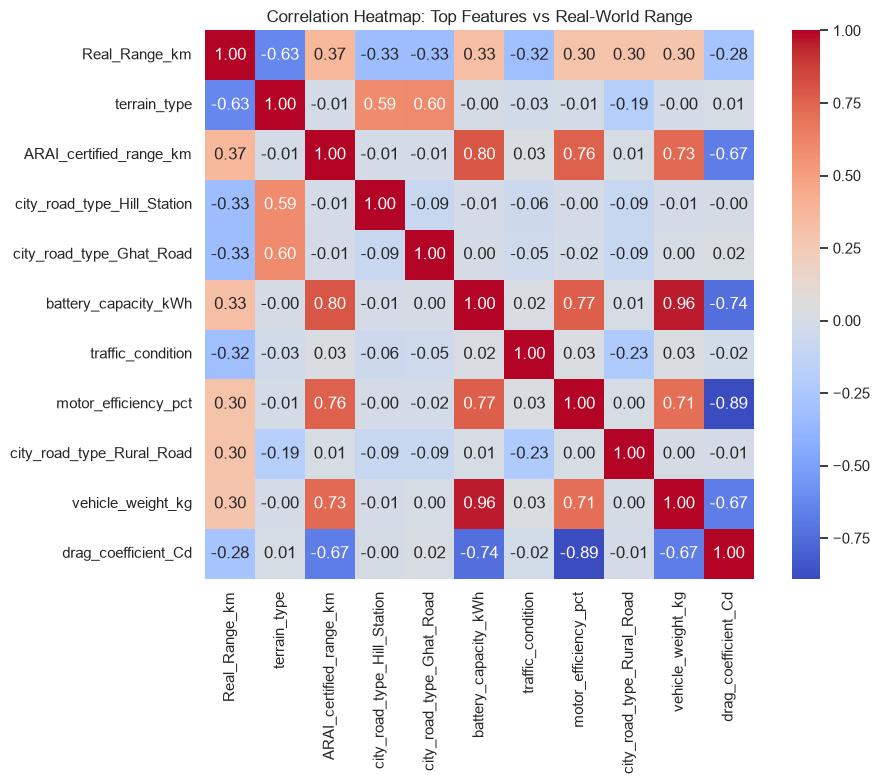

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBRegressor

# Set visual style
sns.set_theme(style="whitegrid")

# 1. Train standalone XGBoost models to extract insights
xgb_energy = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, n_jobs=-1)
xgb_range = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, n_jobs=-1)

xgb_energy.fit(X_train, y1_train)
xgb_range.fit(X_train, y2_train)

# 2. Prepare data for correlation heatmap
df_corr = X_train.copy()
df_corr['Real_Range_km'] = y2_train
corr_matrix = df_corr.corr()

# 3. Get the top 10 features most correlated with Real Range
top_corr_features = corr_matrix['Real_Range_km'].abs().sort_values(ascending=False).head(11).index

# 4. Plot Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df_corr[top_corr_features].corr(), annot=True, cmap="coolwarm", fmt=".2f", square=True)
plt.title("Correlation Heatmap: Top Features vs Real-World Range")
plt.tight_layout()
plt.show()

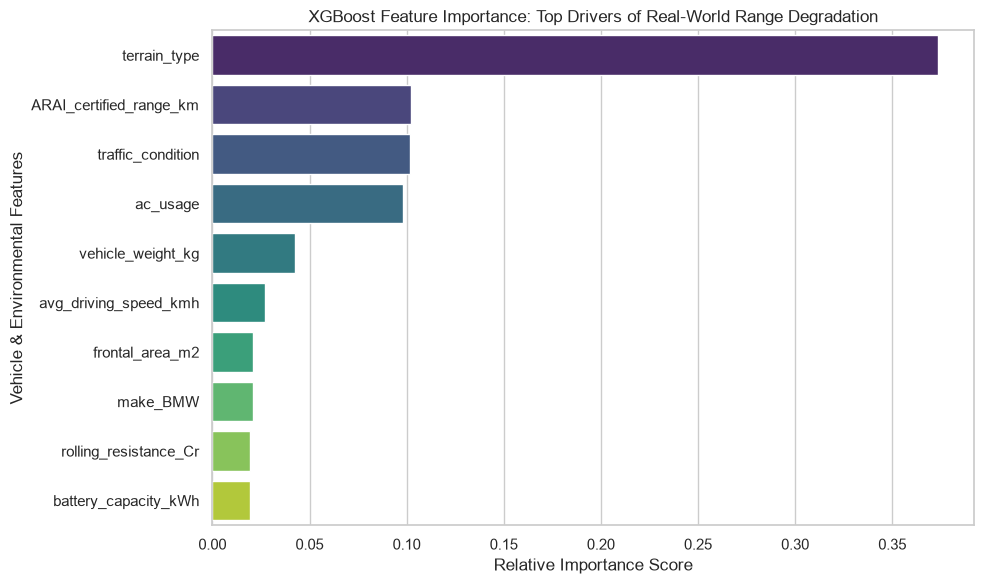

In [8]:
# Extract feature importance scores from the trained XGBoost Range model
plt.figure(figsize=(10, 6))
feature_importances = pd.Series(xgb_range.feature_importances_, index=X_train.columns)
top_features = feature_importances.sort_values(ascending=False).head(10)

# Plot Horizontal Bar Chart
sns.barplot(x=top_features.values, y=top_features.index, hue=top_features.index, palette="viridis", legend=False)
plt.title("XGBoost Feature Importance: Top Drivers of Real-World Range Degradation")
plt.xlabel("Relative Importance Score")
plt.ylabel("Vehicle & Environmental Features")
plt.tight_layout()
plt.show()

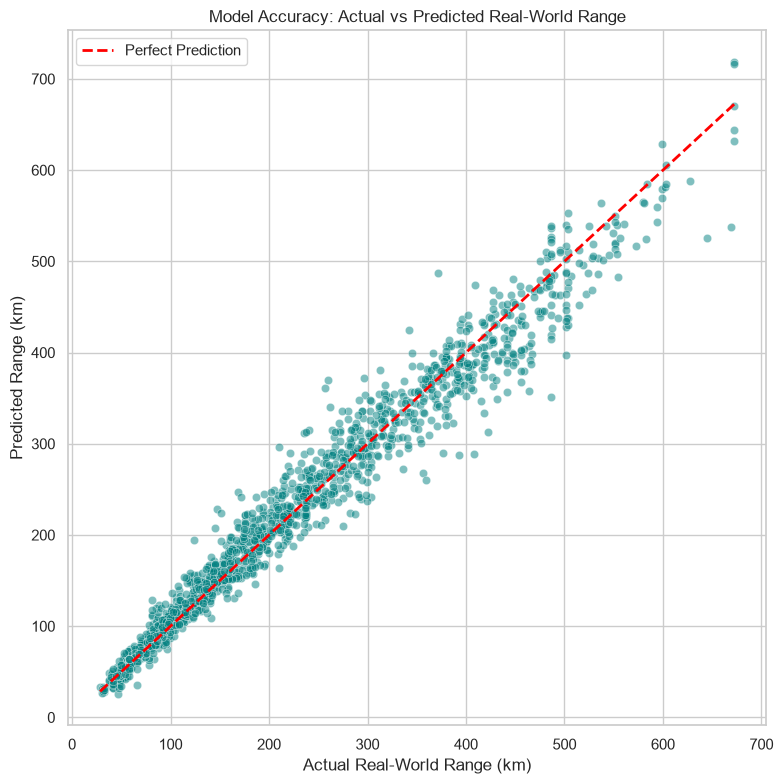

In [9]:
# Generate predictions for the test set
preds_range = xgb_range.predict(X_test)

plt.figure(figsize=(8, 8))
# Plot scatter points
sns.scatterplot(x=y2_test, y=preds_range, alpha=0.5, color="teal")

# Plot perfect prediction 45-degree diagonal line
line_coords = [y2_test.min(), y2_test.max()]
plt.plot(line_coords, line_coords, color="red", linestyle="--", linewidth=2, label="Perfect Prediction")

plt.title("Model Accuracy: Actual vs Predicted Real-World Range")
plt.xlabel("Actual Real-World Range (km)")
plt.ylabel("Predicted Range (km)")
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
import joblib

# Save the models
joblib.dump(xgb_energy, 'model_energy.joblib')
joblib.dump(xgb_range, 'model_range.joblib')

# Save the exact column order so the web app knows how to format user inputs
joblib.dump(X_train.columns.tolist(), 'feature_columns.joblib')

print("Models and features saved! Ready for Streamlit.")

Models and features saved! Ready for Streamlit.


In [11]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import joblib

# Set Page Title & Configuration
st.set_page_config(page_title="EV Range Predictor", layout="wide")

st.title("⚡ Real-World EV Range & Energy Consumption Predictor")
st.write("Input vehicle parameters and environmental factors to estimate real-world range.")

# 1. Load Trained Artifacts
@st.cache_resource
def load_artifacts():
    model_energy = joblib.load('model_energy.joblib')
    model_range = joblib.load('model_range.joblib')
    feature_columns = joblib.load('feature_columns.joblib')
    return model_energy, model_range, feature_columns

model_energy, model_range, feature_columns = load_artifacts()

# 2. Sidebar Inputs for User Parameters
st.sidebar.header("Vehicle & Trip Parameters")

battery_capacity = st.sidebar.number_input("Battery Capacity (kWh)", min_value=10.0, max_value=150.0, value=40.5)
motor_power = st.sidebar.number_input("Motor Power (kW)", min_value=20, max_value=600, value=105)
vehicle_weight = st.sidebar.number_input("Vehicle Weight (kg)", min_value=500, max_value=3500, value=1610)
certified_range = st.sidebar.number_input("ARAI Certified Range (km)", min_value=100, max_value=900, value=465)

avg_speed = st.sidebar.slider("Avg Driving Speed (km/h)", min_value=10, max_value=140, value=45)
ambient_temp = st.sidebar.slider("Ambient Temperature (°C)", min_value=-5, max_value=50, value=30)
ac_usage = st.sidebar.selectbox("AC Usage", options=[0, 1], format_func=lambda x: "On" if x == 1 else "Off")
passengers = st.sidebar.slider("Passengers", min_value=1, max_value=7, value=2)
battery_age = st.sidebar.slider("Battery Age (Years)", min_value=0.0, max_value=10.0, value=1.0, step=0.1)

# Categorical Dropdowns
make_selected = st.sidebar.selectbox("Manufacturer Make", options=["Tata", "MG", "Hyundai", "Mahindra", "BYD", "Smart"])
road_type_selected = st.sidebar.selectbox("Road / City Type", options=["Delhi", "Mumbai", "Pune", "Highway_NH", "Expressway", "Ghat_Road"])

# 3. Predict Button & Logic
if st.button("Predict Range"):
    # Create input dictionary with default 0s for all feature columns
    input_data = {col: 0 for col in feature_columns}
    
    # Fill in numerical features
    input_data['battery_capacity_kWh'] = battery_capacity
    input_data['motor_power_kW'] = motor_power
    input_data['vehicle_weight_kg'] = vehicle_weight
    input_data['ARAI_certified_range_km'] = certified_range
    input_data['avg_driving_speed_kmh'] = avg_speed
    input_data['ambient_temperature_C'] = ambient_temp
    input_data['ac_usage'] = ac_usage
    input_data['passengers'] = passengers
    input_data['battery_age_years'] = battery_age

    # One-hot encoded feature matching
    make_col = f"make_{make_selected}"
    if make_col in input_data:
        input_data[make_col] = 1

    road_col = f"city_road_type_{road_type_selected}"
    if road_col in input_data:
        input_data[road_col] = 1

    # Convert to DataFrame matching exact feature column order
    input_df = pd.DataFrame([input_data])[feature_columns]

    # Predict
    pred_energy = model_energy.predict(input_df)[0]
    pred_range = model_range.predict(input_df)[0]

    # Display Metrics
    col1, col2 = st.columns(2)
    col1.metric(label="Estimated Real-World Range", value=f"{pred_range:.1f} km")
    col2.metric(label="Energy Consumption", value=f"{pred_energy:.3f} kWh/km")

Writing app.py


In [12]:
import os

# List all files in the current folder that end with .joblib
joblib_files = [f for f in os.listdir('.') if f.endswith('.joblib')]
print("Saved Joblib Files:", joblib_files)

Saved Joblib Files: ['feature_columns.joblib', 'model_energy.joblib', 'model_range.joblib']


In [13]:
%%writefile requirements.txt
streamlit
pandas
numpy
xgboost
joblib
scikit-learn

Writing requirements.txt


In [14]:
import os
print(os.getcwd())

C:\Users\HP\anaconda_projects\b7cd5755-c7f3-40a7-afe3-32f46fd41a57
